In [1]:
import os

PATH = '/kaggle/input/datasets/kurumikz/animeomni'

os.listdir(path=PATH)

['000001-000500',
 '001003-001502',
 '001503-002002',
 '002003-002502',
 '002503-003003',
 '003004-003504',
 '003505-004005',
 '004006-004506',
 '004507-005007',
 '005008-005508',
 '005509-006009',
 '006010-006510',
 '006511-007011',
 '007012-007512',
 '007513-008013',
 '008014-008514',
 '008515-009015',
 '009016-009516',
 '009517-010017',
 '010018-010518',
 '010519-011019',
 '011020-011519',
 '011520-012020',
 '012021-012521',
 '012522-013021',
 '013022-013522',
 '013523-014022',
 '014023-014523',
 '014524-015023',
 '015024-015523',
 '015524-016023',
 '016024-016523',
 '016524-017023',
 '017024-017523',
 '017524-018023',
 '018024-018523',
 '018524-019023',
 '019024-019523',
 '019524-020023',
 'LICENSE.txt',
 'README.md']

In [2]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np


DEVICE = torch.device('cpu')
OUTPUT_SIZE = 2048

model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V2)

extraction_layer = model._modules.get('avgpool')
model.to(DEVICE)
model.eval()

scaler = transforms.Resize((224, 224))
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
to_tensor = transforms.ToTensor()

def get_vec(arg, model, extraction_layer):
    image = normalize(to_tensor(scaler(arg))).unsqueeze(0).to(DEVICE)
    result = torch.zeros(1, OUTPUT_SIZE, 1, 1)
    def copy_data(m, i, o):
        result.copy_(o.data)
    hooked = extraction_layer.register_forward_hook(copy_data)
    with torch.no_grad():
        model(image)
    hooked.remove()
    return result

Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 118MB/s]


In [3]:
import arrow
import base64
import pandas as pd
import tqdm

from glob import iglob
from io import BytesIO
from os.path import basename
from os.path import isdir
from PIL import Image

THUMBNAIL_SIZE = (48, 48)

def embed(model, filename: str):
    try:
        with Image.open(fp=filename, mode='r') as image:
            return get_vec(arg=image.convert('RGB'), model=model, extraction_layer=extraction_layer).numpy().reshape(OUTPUT_SIZE,)
    except: 
        print(filename)
        return None


# https://stackoverflow.com/a/952952
def flatten(arg):
    return [x for xs in arg for x in xs]

def png(filename: str) -> str:
    with Image.open(fp=filename, mode='r') as image:
        buffer = BytesIO()
        image.resize(size=THUMBNAIL_SIZE).convert('RGB').save(buffer, format='png')
        return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

def get_picture_from_glob(arg: str, tag: str,) -> list:
    input_files = list(iglob(pathname=arg))
    input_files = [item for item in input_files if (item.endswith('.jpg') or item.endswith('.jpeg'))]
    input_files = input_files[:100]
    result = [pd.Series(data=[tag, basename(input_file), embed(model=model, filename=input_file), png(filename=input_file)],
                        index=['tag', 'name', 'value', 'png'])
        for index, input_file in enumerate(tqdm.tqdm(desc=tag, iterable=input_files)) ]
    return result

time_start = arrow.now()
train_dict = {basename(folder) : folder + '/data/*.*' for folder in iglob(PATH + '/*') if isdir(folder) }
train_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key) for (key, value) in train_dict.items()]))
print('done in {}'.format(arrow.now() - time_start))

019524-020023: 100%|██████████| 100/100 [00:23<00:00,  4.17it/s]


done in 0:15:59.358158


In [4]:
train_df['tag'].value_counts().to_frame().T

tag,000001-000500,001003-001502,001503-002002,002003-002502,002503-003003,003004-003504,003505-004005,004006-004506,004507-005007,005008-005508,...,015024-015523,015524-016023,016024-016523,016524-017023,017024-017523,017524-018023,018024-018523,018524-019023,019024-019523,019524-020023
count,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100


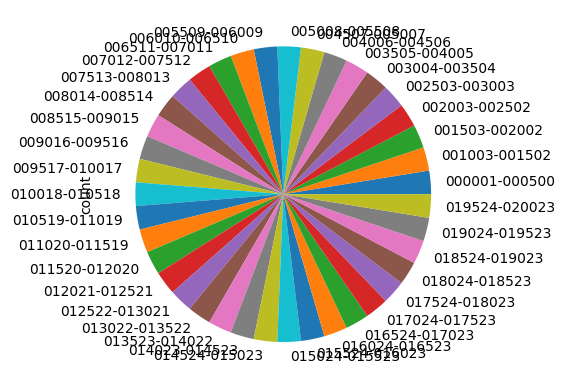

In [5]:
import matplotlib.pyplot as plt

train_df['tag'].value_counts().to_frame().plot(kind='pie', subplots=True, legend=False)
plt.show()

In [6]:
from sklearn.manifold import TSNE

train_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
train_df[['x', 'y']] = train_reducer.fit_transform(X=train_df['value'].apply(func=pd.Series))

[t-SNE] Computing 61 nearest neighbors...
[t-SNE] Indexed 3900 samples in 0.023s...
[t-SNE] Computed neighbors for 3900 samples in 1.503s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3900
[t-SNE] Computed conditional probabilities for sample 2000 / 3900
[t-SNE] Computed conditional probabilities for sample 3000 / 3900
[t-SNE] Computed conditional probabilities for sample 3900 / 3900
[t-SNE] Mean sigma: 2.964365
[t-SNE] KL divergence after 250 iterations with early exaggeration: 85.790207
[t-SNE] KL divergence after 1000 iterations: 2.700111


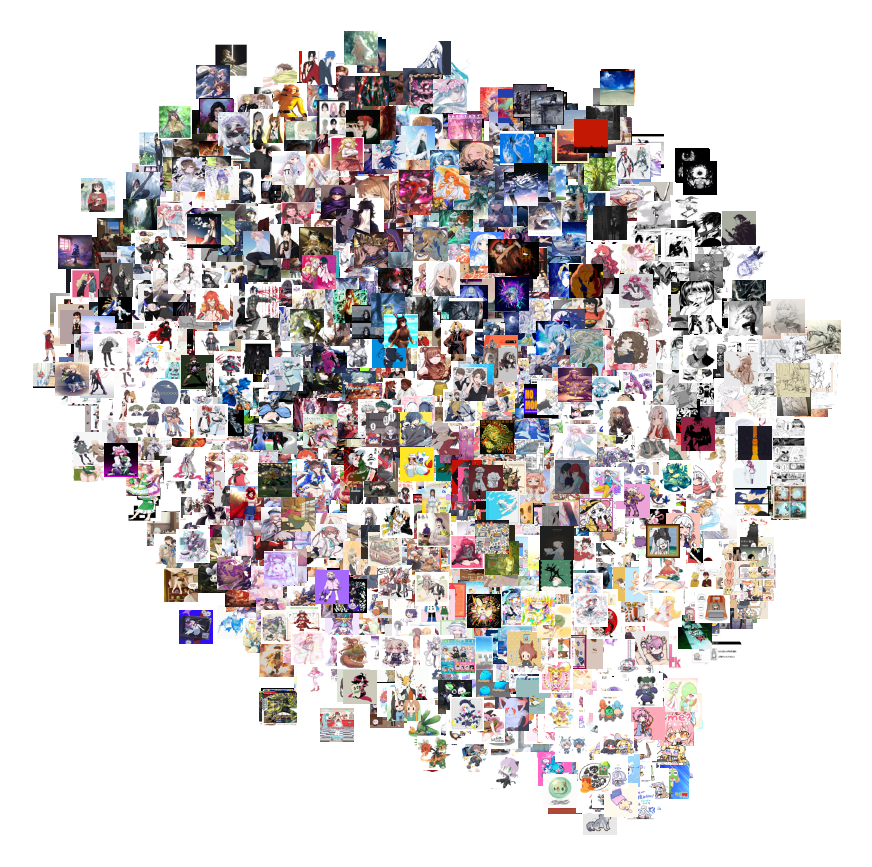

In [7]:
import base64
import io
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image

# we recycled some PNG encoding code above, and we need to postprocess it for using with matplotlib
train_df['PNG'] = train_df['png'].str.replace('^data:image/png;base64,', '', regex=True)
plot_df = train_df.sample(n=2500, random_state=2026) if len(train_df) > 2501 else train_df.copy()
fig, ax = plt.subplots(figsize=(11, 11))

for index, row in plot_df.iterrows():
    img_bytes = base64.b64decode(row["PNG"])
    img = Image.open(io.BytesIO(img_bytes))
    imagebox = OffsetImage(img, zoom=0.5)
    ab = AnnotationBbox(imagebox, (row["x"], row["y"]), frameon=False, pad=0)
    ax.add_artist(ab)
ax.scatter(plot_df["x"], plot_df["y"], alpha=0)
ax.axis('off')
plt.show()

In [8]:
from bokeh.models import ColumnDataSource
from bokeh.models import HoverTool

from bokeh.plotting import figure
from bokeh.plotting import output_notebook
from bokeh.plotting import show
from bokeh.palettes import Turbo256
from bokeh.transform import factor_cmap

output_notebook()

datasource = ColumnDataSource(train_df[['png', 'tag', 'x', 'y']].sample(n=min(len(train_df) - 1, 10000)))
factor_count = max(train_df['tag'].nunique(), 3)
indices = np.linspace(0, len(Turbo256)-1, factor_count, dtype=int)
palette = [Turbo256[index] for index in indices]
mapper = factor_cmap(field_name = 'tag', palette=palette, factors=train_df['tag'].unique().tolist(), start=0, end=factor_count-1, )

plot_figure = figure(title='TSNE projection: AnimeOmni', width=1000, height=800, tools=('pan, wheel_zoom, reset'))

plot_figure.add_tools(HoverTool(tooltips="""
<div>
    <div>
        <img src='@png' style='float: left; margin: 5px 5px 5px 5px'/>
    </div>
    <div>
        <span style='font-size: 18px'>@tag</span>
    </div>
</div>
"""))

plot_figure.scatter(x='x', y='y', source=datasource, line_alpha=0.6, fill_alpha=0.6, size=8, color=mapper)
show(plot_figure)

Loading BokehJS ...

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(train_df['value'].apply(pd.Series), train_df['tag'], test_size=0.2, random_state=14, stratify=train_df['tag'])
logreg = LogisticRegression(max_iter=2000, tol=1e-12).fit(X_train, y_train)
print('model fit in {} iterations'.format(logreg.n_iter_[0]))
print('accuracy: {:5.4f}'.format(accuracy_score(y_true=y_test, y_pred=logreg.predict(X=X_test))))
print('f1: {:5.4f}'.format(f1_score(average='weighted', y_true=y_test, y_pred=logreg.predict(X=X_test))))
print(classification_report(y_true=y_test, y_pred=logreg.predict(X=X_test), zero_division=0.0))

model fit in 955 iterations
accuracy: 0.0821
f1: 0.0809
               precision    recall  f1-score   support

000001-000500       0.06      0.10      0.08        20
001003-001502       0.17      0.20      0.18        20
001503-002002       0.05      0.05      0.05        20
002003-002502       0.05      0.05      0.05        20
002503-003003       0.00      0.00      0.00        20
003004-003504       0.17      0.20      0.18        20
003505-004005       0.08      0.05      0.06        20
004006-004506       0.05      0.05      0.05        20
004507-005007       0.11      0.10      0.11        20
005008-005508       0.08      0.10      0.09        20
005509-006009       0.12      0.15      0.13        20
006010-006510       0.11      0.10      0.10        20
006511-007011       0.23      0.15      0.18        20
007012-007512       0.06      0.05      0.06        20
007513-008013       0.05      0.05      0.05        20
008014-008514       0.07      0.10      0.08        20
008515-0

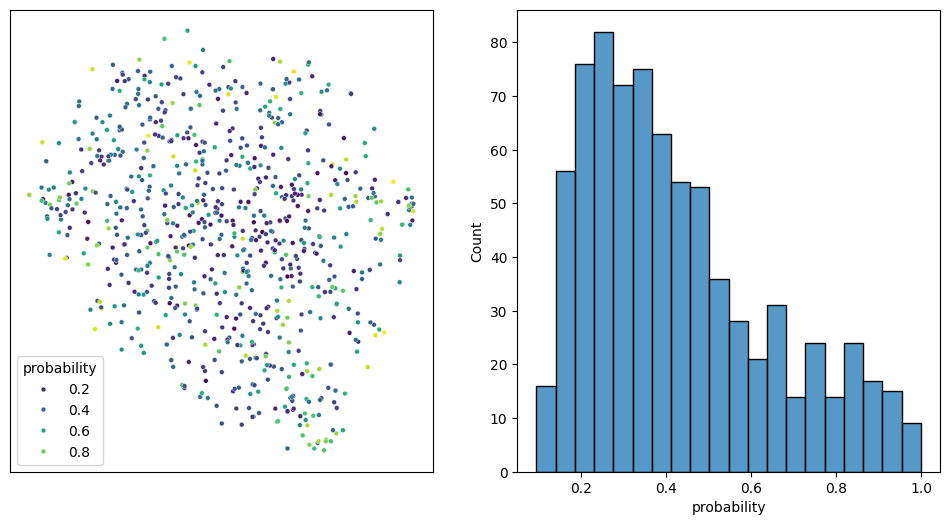

In [10]:
import warnings
from seaborn import histplot
from seaborn import scatterplot

warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

plot_df = train_df.iloc[X_test.index][['x', 'y']].copy()
plot_df['probability'] = np.max(logreg.predict_proba(X=X_test), axis=1)

fig, ax = plt.subplots(ncols=2, figsize=(12, 6))
scatterplot(ax=ax[0], data=plot_df, x='x', y='y', hue='probability', palette='viridis', s=12)
ax[0].set(xlabel=None) 
ax[0].set(ylabel=None)
ax[0].set(xticklabels=[])
ax[0].set(yticklabels=[])
ax[0].tick_params(axis='both', which='both', length=0)
histplot(ax=ax[1], data=plot_df, x='probability', bins=20)
fig.show()